# 1.1 Importing important libraries , modules and functions


In [1]:
import pandas as pd                 
import numpy as np                   
import matplotlib.pyplot as plt      
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1.2.1 Reading the Dataset

In [2]:
#https://www.kaggle.com/datasets/ayeshaseherr/diamonds
df = pd.read_csv('../Data/diamonds.csv')

# 1.2.2 Analysing the Data

In [3]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types and null values info:")
df.info()
print("\nSummary of numeric columns:")
df.describe()

Dataset dimensions: (53940, 11)

Column names:
['S.No.', 'carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

Data types and null values info:
<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   S.No.    53940 non-null  int64  
 1   carat    53940 non-null  float64
 2   cut      53940 non-null  str    
 3   color    53940 non-null  str    
 4   clarity  53940 non-null  str    
 5   depth    53940 non-null  float64
 6   table    53940 non-null  float64
 7   price    53940 non-null  int64  
 8   x        53940 non-null  float64
 9   y        53940 non-null  float64
 10  z        53940 non-null  float64
dtypes: float64(6), int64(2), str(3)
memory usage: 4.5 MB

Summary of numeric columns:


,S.No.,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,26970.500000,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,53940.000000,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


# 1.3 Selecting Numeric Columns

In [4]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_columns)

Numeric columns: ['S.No.', 'carat', 'depth', 'table', 'price', 'x', 'y', 'z']


# 1.4 Visual Analysis of the Data

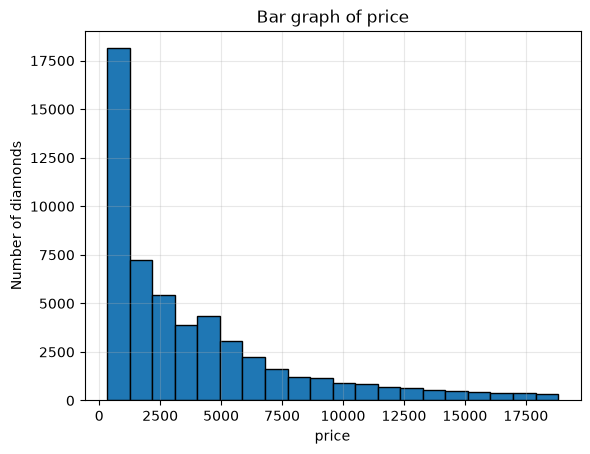

In [5]:
#Bar graph
Plot_column=numeric_columns[4]
plt.hist(df[Plot_column].dropna(), bins=20, edgecolor="Black")
plt.title(f"Bar graph of {Plot_column}")
plt.xlabel(Plot_column)
plt.ylabel("Number of diamonds")
plt.grid(alpha=0.29)
plt.show()

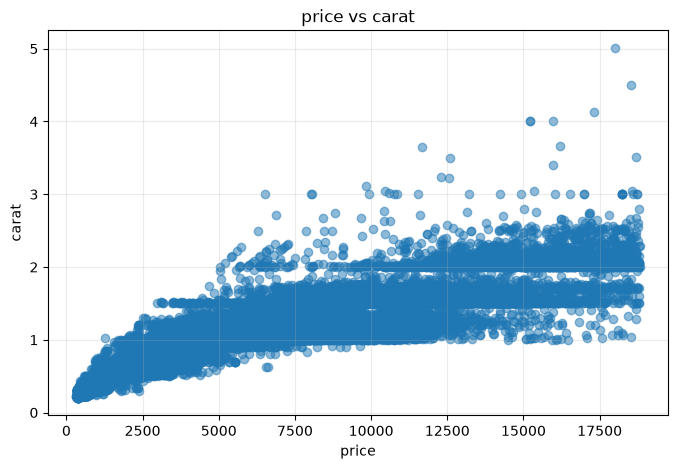

In [6]:
#Scatter plot
Y_axis=numeric_columns[1]
X_axis=numeric_columns[4]

plt.figure(figsize=(8, 5))
plt.scatter(df[X_axis], df[Y_axis], alpha=0.5)
plt.title(f"{X_axis} vs {Y_axis}")
plt.xlabel(X_axis)
plt.ylabel(Y_axis)
plt.grid(alpha=0.25)
plt.show()

# 1.5 Preprocessing Of Data

In [7]:
print("Rows with a zero dimension:", (df[["x", "y", "z"]] == 0).any(axis=1).sum())

Rows with a zero dimension: 20


In [8]:

df_processed = df.drop_duplicates().copy()


required_columns = ["carat", "cut", "color", "clarity", "price"]
missing_columns = [
    column for column in required_columns
    if column not in df_processed.columns
]

if missing_columns:
    print("Error: These columns do not exist:", missing_columns)
    # The program should stop its execution now
    raise ValueError("Stopping execution because required columns are missing.") 

else:
    df_processed = df_processed[required_columns].copy()
    

    
    X = df_processed[["carat", "cut", "color", "clarity"]]
    y = df_processed["price"]

    # One hot encoding
    #I used this get_dummies(which i found online) command instead of tradidtional transforming to transform beacause it was easier
    X = pd.get_dummies(
        X,
        columns=["cut", "color", "clarity"],
        dtype=int
    )

    print(f"No. of missing values : {df.isnull().sum().sum()}")
    # Since there are 0 missing values , we didnot make numerical and column transformer to fill missing values
    print("Features:", X.columns.tolist())
    print("Target:", y.name)
    print("Rows available for modelling:", len(df_processed))

No. of missing values : 0
Features: ['carat', 'cut_Fair', 'cut_Good', 'cut_Ideal', 'cut_Premium', 'cut_Very Good', 'color_D', 'color_E', 'color_F', 'color_G', 'color_H', 'color_I', 'color_J', 'clarity_I1', 'clarity_IF', 'clarity_SI1', 'clarity_SI2', 'clarity_VS1', 'clarity_VS2', 'clarity_VVS1', 'clarity_VVS2']
Target: price
Rows available for modelling: 53940


# 1.6 Split into training and testing data

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 43152
Testing examples: 10788


<h1> 1.7 Building and Training the Model</h1>

In [10]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train,y_train)
print("Diamond Price Model Training Completed!")

Diamond Price Model Training Completed!


<h1> 1.8.1  Making Predictions</h1>

In [11]:
y_pred = model.predict(X_test)
comparision = pd.DataFrame({
    'Actual price':y_test,
    'Predicted price':y_pred,
    'Error':y_test - y_pred
})
display(comparision.head(10))

,Actual price,Predicted price,Error
1388,559,330.455184,228.544816
50052,2201,3309.950127,-1108.950127
41645,1238,1949.682676,-711.682676
42377,1304,2080.865102,-776.865102
17244,6901,9837.823921,-2936.823921
1608,3011,3920.949078,-909.949078
46398,1765,2400.204424,-635.204424
45493,1679,2475.195567,-796.195567
49385,2102,3010.798845,-908.798845
10460,4789,6371.093493,-1582.093493


<h1> 1.8.2  Predicting the price of a new diamond</h1>

In [12]:
new_diamond = pd.DataFrame({
    'carat': [0.75],
    'cut': ['Good'],
    'color': ['F'],
    'clarity': ['VS2'],
    'depth': [61.8],
    'table': [56.0],
    'x': [5.1],
    'y': [5.15],
    'z': [3.15]
})

new_diamond = pd.get_dummies(
    new_diamond,
    columns=['cut', 'color', 'clarity'],
    dtype=int
)

new_diamond = new_diamond.reindex(
    columns=X.columns,
    fill_value=0
)

# Predict the diamond price
predicted_price = model.predict(new_diamond)

print("Predicted Diamond Price:", predicted_price[0])

Predicted Diamond Price: 3858.7484357471094


# 1.9 Evaluating the model

In [13]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:,.3f}")
print(f"MSE  : {mse:,.3f}")
print(f"RMSE : {rmse:,.3f}")
print(f"R²   : {r2:.3f}")

MAE  : 802.116
MSE  : 1,346,335.590
RMSE : 1,160.317
R²   : 0.915


# 1.10  Visualize actual vs predicted prices

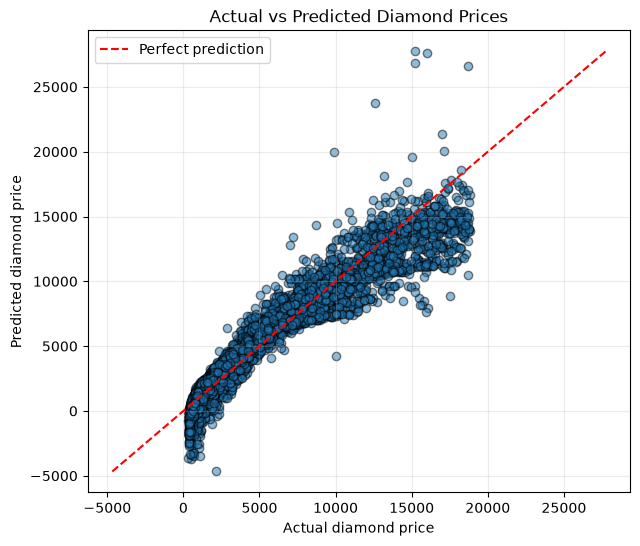

In [14]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolor="black")

low = min(float(np.min(y_test)), float(np.min(y_pred)))
high = max(float(np.max(y_test)), float(np.max(y_pred)))
plt.plot([low, high], [low, high], linestyle="--", color="red", label="Perfect prediction")

plt.xlabel("Actual diamond price")
plt.ylabel("Predicted diamond price")
plt.title("Actual vs Predicted Diamond Prices")
plt.legend()
plt.grid(alpha=0.25)
plt.show()